<a href="https://colab.research.google.com/github/ReemaKhalaf1/INTELLIGENT-SYSTEM1-CI512/blob/main/Tutorial4_Heart_Disease_Classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


In [3]:
import zipfile

with zipfile.ZipFile('archive.zip', 'r') as zip_ref:
    zip_ref.extractall('heart_data')

print("Files extracted successfully!")

Files extracted successfully!


In [4]:
import os

for root, dirs, files in os.walk('heart_data'):
    for file in files:
        print(os.path.join(root, file))

heart_data/heart.csv


In [5]:
import pandas as pd

df = pd.read_csv('heart_data/heart.csv')

print(df.shape)
print(df.columns.tolist())

df.head()

(1025, 14)
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [6]:
import pandas as pd
import os

for root, dirs, files in os.walk('heart_data'):
    for file in files:
        if file.endswith('.csv'):
            print(os.path.join(root, file))

heart_data/heart.csv


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [8]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

Missing values:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64

Duplicate rows:
723


In [9]:
df.describe()


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,1025.000000,1025.000000,1025.000000,1025.000000,1025.00000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000,1025.000000
mean,54.434146,0.695610,0.942439,131.611707,246.00000,0.149268,0.529756,149.114146,0.336585,1.071512,1.385366,0.754146,2.323902,0.513171
std,9.072290,0.460373,1.029641,17.516718,51.59251,0.356527,0.527878,23.005724,0.472772,1.175053,0.617755,1.030798,0.620660,0.500070
min,29.000000,0.000000,0.000000,94.000000,126.00000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,48.000000,0.000000,0.000000,120.000000,211.00000,0.000000,0.000000,132.000000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,56.000000,1.000000,1.000000,130.000000,240.00000,0.000000,1.000000,152.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,275.00000,0.000000,1.000000,166.000000,1.000000,1.800000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.00000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [10]:
print(df['target'].value_counts())

print("\nTarget percentages:")
print(df['target'].value_counts(normalize=True) * 100)

target
1    526
0    499
Name: count, dtype: int64

Target percentages:
target
1    51.317073
0    48.682927
Name: proportion, dtype: float64


<Axes: title={'center': 'Distribution of Target Classes'}, xlabel='Target', ylabel='Number of Records'>

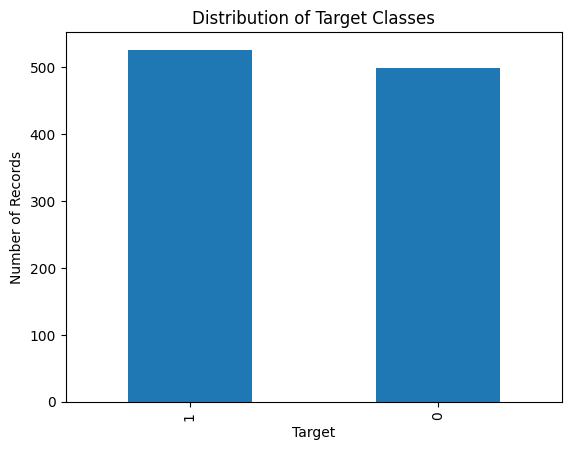

In [11]:
df['target'].value_counts().plot(
    kind='bar',
    title='Distribution of Target Classes',
    xlabel='Target',
    ylabel='Number of Records'
)

In [13]:

print("=" * 40)
print("1. DATASET SHAPE")
print("=" * 40)
print(df.shape)

print("\n" + "=" * 40)
print("2. MISSING VALUES")
print("=" * 40)
print(df.isnull().sum())
print("Total missing values:", df.isnull().sum().sum())

print("\n" + "=" * 40)
print("3. DUPLICATE ROWS")
print("=" * 40)
print("Duplicate rows:", df.duplicated().sum())

print("\n" + "=" * 40)
print("4. STATISTICAL SUMMARY")
print("=" * 40)
print(df.describe().round(2).to_string())

print("\n" + "=" * 40)
print("5. TARGET DISTRIBUTION")
print("=" * 40)
print(df['target'].value_counts().to_string())

print("\nTarget percentages:")
print((df['target'].value_counts(normalize=True) * 100).round(2).to_string())


1. DATASET SHAPE
(1025, 14)

2. MISSING VALUES
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
Total missing values: 0

3. DUPLICATE ROWS
Duplicate rows: 723

4. STATISTICAL SUMMARY
           age      sex       cp  trestbps     chol      fbs  restecg  thalach    exang  oldpeak    slope       ca     thal   target
count  1025.00  1025.00  1025.00   1025.00  1025.00  1025.00  1025.00  1025.00  1025.00  1025.00  1025.00  1025.00  1025.00  1025.00
mean     54.43     0.70     0.94    131.61   246.00     0.15     0.53   149.11     0.34     1.07     1.39     0.75     2.32     0.51
std       9.07     0.46     1.03     17.52    51.59     0.36     0.53    23.01     0.47     1.18     0.62     1.03     0.62     0.50
min      29.00     0.00     0.00     94.00   126.00     0.00     0.00    71.00     0.00     0.00     0.00     0.00     0.00  

In [14]:
# Check the number of unique rows
df_unique = df.drop_duplicates()

print("Original dataset shape:", df.shape)
print("Dataset shape after removing duplicates:", df_unique.shape)

print("\nTarget distribution after removing duplicates:")
print(df_unique['target'].value_counts())

print("\nTarget percentages after removing duplicates:")
print(
    (df_unique['target'].value_counts(normalize=True) * 100).round(2)
)

Original dataset shape: (1025, 14)
Dataset shape after removing duplicates: (302, 14)

Target distribution after removing duplicates:
target
1    164
0    138
Name: count, dtype: int64

Target percentages after removing duplicates:
target
1    54.3
0    45.7
Name: proportion, dtype: float64


In [15]:
df_unique = df.drop_duplicates()

print("Original dataset:", df.shape)
print("After removing duplicates:", df_unique.shape)

print("\nTarget distribution:")
print(df_unique['target'].value_counts())

print("\nTarget percentages:")
print(
    (df_unique['target'].value_counts(normalize=True) * 100).round(2)
)

Original dataset: (1025, 14)
After removing duplicates: (302, 14)

Target distribution:
target
1    164
0    138
Name: count, dtype: int64

Target percentages:
target
1    54.3
0    45.7
Name: proportion, dtype: float64


In [16]:
# Use the dataset after removing duplicate rows
df = df_unique.copy()

# Separate features and target
X = df.drop('target', axis=1)
y = df['target']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nFeature columns:")
print(X.columns.tolist())

Features shape: (302, 13)
Target shape: (302,)

Feature columns:
['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [17]:

from sklearn.model_selection import train_test_split

# Split data into training (80%) and testing (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts(normalize=True).round(3))

print("\nTesting target distribution:")
print(y_test.value_counts(normalize=True).round(3))

Training data: (241, 13)
Testing data: (61, 13)

Training target distribution:
target
1    0.544
0    0.456
Name: proportion, dtype: float64

Testing target distribution:
target
1    0.541
0    0.459
Name: proportion, dtype: float64


In [18]:

from sklearn.preprocessing import StandardScaler

# Continuous numerical features
columns_to_scale = [
    'age',
    'trestbps',
    'chol',
    'thalachh',
    'oldpeak'
]

# Create a copy of the datasets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Create and fit the scaler on training data only
scaler = StandardScaler()

X_train_scaled[columns_to_scale] = scaler.fit_transform(
    X_train[columns_to_scale]
)

# Apply the same transformation to test data
X_test_scaled[columns_to_scale] = scaler.transform(
    X_test[columns_to_scale]
)

print("Training data after scaling:")
display(X_train_scaled.head())

print("\nTesting data after scaling:")
display(X_test_scaled.head())


KeyError: "['thalachh'] not in index"

In [19]:
print(X_train.columns.tolist())

['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']


In [20]:

from sklearn.preprocessing import StandardScaler

# Continuous numerical features
columns_to_scale = [
    'age',
    'trestbps',
    'chol',
    'thalach',
    'oldpeak'
]

# Create copies of the datasets
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit the scaler using training data only
scaler = StandardScaler()

X_train_scaled[columns_to_scale] = scaler.fit_transform(
    X_train[columns_to_scale]
)

# Apply the same scaling to the test data
X_test_scaled[columns_to_scale] = scaler.transform(
    X_test[columns_to_scale]
)

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nFirst five training records:")
display(X_train_scaled.head())


Training data shape: (241, 13)
Testing data shape: (61, 13)

First five training records:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
158,1.421944,0,2,-0.973041,5.882908,0,0,0.408240,0,0.527263,1,0,3
199,-0.465841,1,0,0.756507,-0.885696,0,0,-1.104705,1,-0.083233,1,0,3
479,0.422528,1,0,-0.197726,-0.588175,0,0,-0.882213,1,1.050546,1,3,3
460,1.644036,1,2,0.517949,0.118437,0,0,-0.214737,0,0.876119,1,3,3
169,-1.021072,0,1,-1.151959,-1.629499,0,1,-0.570724,0,-0.868157,1,0,2


In [21]:
from tensorflow import keras
from keras import Sequential
from keras.layers import Input, Dense

# Create the neural network
model = Sequential([
    Input(shape=(13,)),
    Dense(13, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
])

# Configure the model for training
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display the model architecture
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 13)             │           182 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 303 (1.18 KB)

 Trainable params: 303 (1.18 KB)

 Non-trainable params: 0 (0.00 B)

In [22]:
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 6s 372ms/step - accuracy: 0.4740 - loss: 0.7070 - val_accuracy: 0.3878 - val_loss: 0.7841
Epoch 2/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.4740 - loss: 0.6863 - val_accuracy: 0.4286 - val_loss: 0.7539
Epoch 3/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.5000 - loss: 0.6646 - val_accuracy: 0.4490 - val_loss: 0.7284
Epoch 4/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 65ms/step - accuracy: 0.5260 - loss: 0.6491 - val_accuracy: 0.5102 - val_loss: 0.7063
Epoch 5/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.5729 - loss: 0.6348 - val_accuracy: 0.5306 - val_loss: 0.6887
Epoch 6/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 68ms/step - accuracy: 0.6198 - loss: 0.6237 - val_accuracy: 0.5306 - val_loss: 0.6745
Epoch 7/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step - accuracy: 0.6250 - loss: 0.6151 - val_accuracy: 0.5510 - val_loss: 0.6622
Epoch 8/100
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/step - accuracy: 0.6562 - loss: 0.6057 - val_accuracy: 0.5714 - val_loss

In [23]:
# Evaluate the model on training data
train_loss, train_accuracy = model.evaluate(
    X_train_scaled, y_train, verbose=0
)

# Evaluate the model on unseen test data
test_loss, test_accuracy = model.evaluate(
    X_test_scaled, y_test, verbose=0
)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")

print(f"Training Loss: {train_loss:.4f}")
print(f"Testing Loss: {test_loss:.4f}")

Training Accuracy: 87.97%
Testing Accuracy: 73.77%
Training Loss: 0.2862
Testing Loss: 0.5803


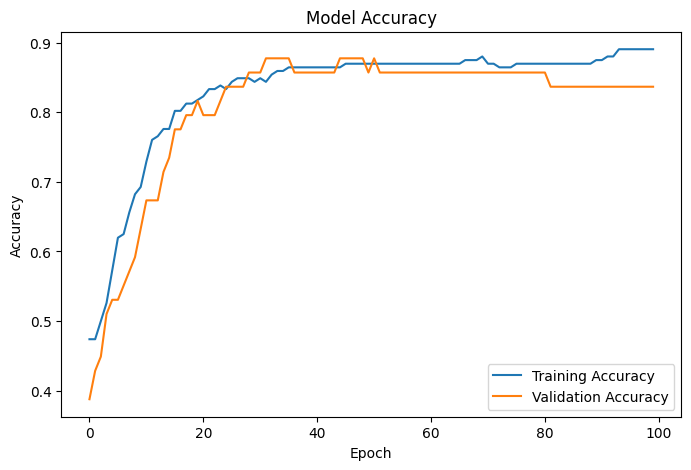

In [24]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

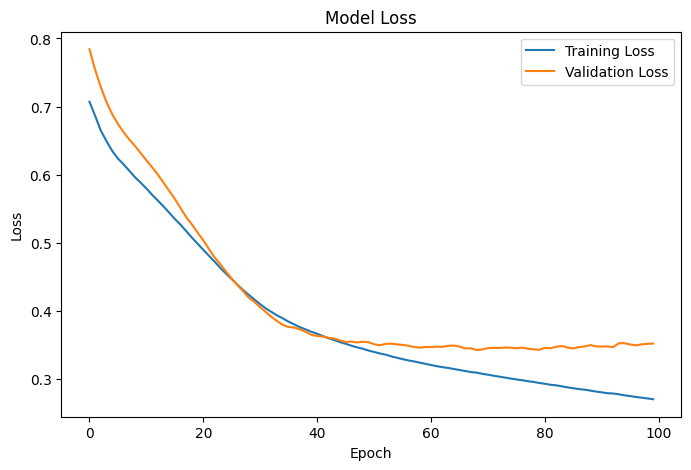

In [25]:
plt.figure(figsize=(8, 5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 181ms/step


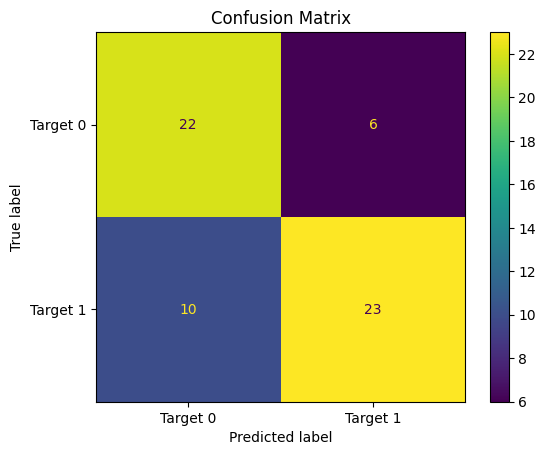

              precision    recall  f1-score   support

    Target 0       0.69      0.79      0.73        28
    Target 1       0.79      0.70      0.74        33

    accuracy                           0.74        61
   macro avg       0.74      0.74      0.74        61
weighted avg       0.74      0.74      0.74        61



In [26]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import classification_report
import matplotlib.pyplot as plt
import numpy as np

# Predict probabilities for the test data
y_prob = model.predict(X_test_scaled)

# Convert probabilities into classes
y_pred = (y_prob >= 0.5).astype(int).ravel()

# Display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Target 0', 'Target 1']
)

disp.plot()
plt.title('Confusion Matrix')
plt.show()

# Display precision, recall, and F1-score
print(classification_report(
    y_test,
    y_pred,
    target_names=['Target 0', 'Target 1'],
    zero_division=0
))

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


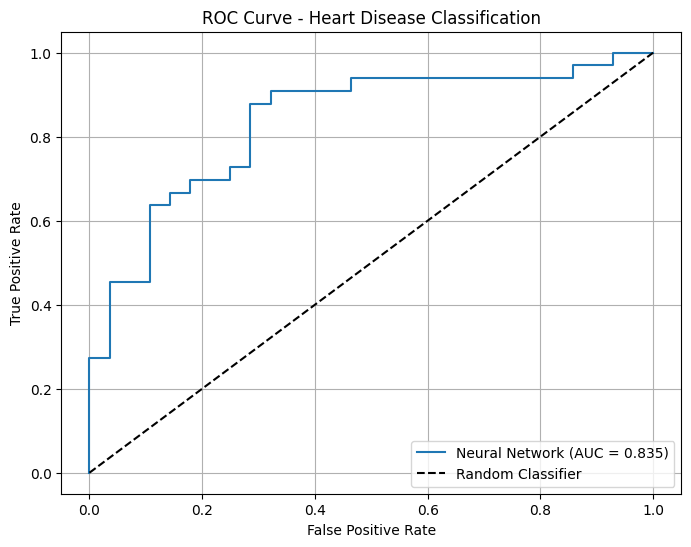

AUC Score: 0.8355


In [27]:

from sklearn.metrics import roc_curve, roc_auc_score
import matplotlib.pyplot as plt

# Predict probabilities for the test data
y_test_probs = model.predict(X_test_scaled).ravel()

# Calculate ROC curve values
fpr, tpr, thresholds = roc_curve(y_test, y_test_probs)

# Calculate AUC score
auc_score = roc_auc_score(y_test, y_test_probs)

# Plot the ROC curve
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, label=f'Neural Network (AUC = {auc_score:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier')

plt.title('ROC Curve - Heart Disease Classification')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f'AUC Score: {auc_score:.4f}')


In [28]:
# Select a single record from the test set (e.g., the first record)
single_record = X_test.iloc[[0]]
actual_label = y_test.iloc[0]

# Make a prediction with the loaded model
# Keras models expect a batch input, so we pass a DataFrame with 1 row
raw_prediction = new_model.predict(single_record)

# Threshold the raw probability to get the predicted binary class
predicted_class = int(raw_prediction[0][0] > 0.5)
class_labels = {0: 'No Heart Disease', 1: 'Heart Disease'}

# Display the results
print("=== Single Record Prediction Example ===")
print("\nInput Features:")
display(single_record)
print(f"\nPredicted Probability: {raw_prediction[0][0]:.4f}")
print(f"Predicted Class: {predicted_class} ({class_labels[predicted_class]})")
print(f"Actual Class: {actual_label} ({class_labels[actual_label]})")

NameError: name 'new_model' is not defined

In [29]:

# Select a single record from the test set
single_record = X_test_scaled.iloc[[0]]
actual_label = int(y_test.iloc[0])

# Make a prediction using the trained model
raw_prediction = model.predict(single_record, verbose=0)

# Convert the predicted probability into a class
predicted_class = int(raw_prediction[0][0] >= 0.5)

# Define the class labels
class_labels = {
    0: 'Target 0',
    1: 'Target 1'
}

# Display the results
print("=== Single Record Prediction Example ===")

print("\nInput Features:")
display(single_record)

print(f"\nPredicted Probability: {raw_prediction[0][0]:.4f}")

print(
    f"Predicted Class: {predicted_class} "
    f"({class_labels[predicted_class]})"
)

print(
    f"Actual Class: {actual_label} "
    f"({class_labels[actual_label]})"
)

if predicted_class == actual_label:
    print("\nResult: Correct prediction!")
else:
    print("\nResult: Incorrect prediction.")


=== Single Record Prediction Example ===

Input Features:


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
25,0.755667,0,0,0.816147,1.103976,0,0,-0.214737,1,0.003981,1,0,3



Predicted Probability: 0.0489
Predicted Class: 0 (Target 0)
Actual Class: 0 (Target 0)

Result: Correct prediction!
